# Part 3 – Portfolio of Evidence: Image Recognition with CNNs
**Module:** Programming for Data Analytics 2 (PDAN8412/w)  
**Assessment:** Portfolio of Evidence – CNNs (100 marks)  
**Case study:** Image recognition proof of concept for a book publisher  
**Dataset:** CIFAR-10 (60,000 labelled colour images; 10 classes)


## 1. Problem definition and project objectives

The publisher is investigating image recognition as a first step towards automated visual identification at its premises. This project develops a CNN that classifies general images into ten predefined categories. CIFAR-10 is appropriate for demonstrating image classification, but it is **not a facial-recognition dataset** and this model must not be represented as a deployable security or identity-verification system.

**Objectives**
1. Assess dataset suitability and quality.
2. Inspect image dimensions, class distribution and representative images.
3. Prepare the image data for CNN training.
4. Train a baseline CNN in TensorFlow/Keras.
5. Evaluate the model using accuracy, precision, recall, F1-score and a confusion matrix.
6. Improve the model through augmentation, regularisation and/or training adjustments, then compare results.
7. Communicate findings, limitations and recommendations in a concise client report.

## 2. Dataset evaluation and justification

CIFAR-10 contains 60,000 RGB images of size 32 × 32 pixels: 50,000 training images and 10,000 test images. The images are distributed across ten mutually exclusive classes. The dataset is widely used for benchmarking image-classification methods.

**Suitability:** It contains labelled image data, multiple visual categories, colour channels and enough records to exceed the assessment minimum of 10,000. The predefined labels support supervised multiclass classification.

**Quality considerations and limitations:** Images are low resolution, objects may be small or partially obscured, and real-world images can differ from this curated dataset. Class balance must be checked rather than assumed. The fixed train/test split must be preserved; the test set must not be used for tuning. CIFAR-10 does not contain faces or identity labels, so it cannot validate facial recognition.

**Dataset source:** https://www.cs.toronto.edu/~kriz/cifar.html  
**Loader documentation:** https://www.tensorflow.org/api_docs/python/tf/keras/datasets/cifar10

## 3. Analysis plan

| Stage | Planned activities | Evidence/output |
|---|---|---|
| Data acquisition | Load CIFAR-10 and confirm sample counts | Dataset shapes and source |
| EDA | Inspect labels, image dimensions, pixel ranges, class frequencies and sample images | Tables and visualisations |
| Data preparation | Check missing/invalid values, scale pixels, encode labels, create validation split | Prepared arrays |
| Feature learning | Allow convolution and pooling layers to learn spatial features automatically | CNN architecture |
| Baseline training | Train a compact CNN with fixed seed, validation monitoring and early stopping | Training history |
| Evaluation | Test accuracy/loss; class-wise precision, recall and F1; confusion matrix | Evaluation metrics |
| Improvement | Apply augmentation, dropout and batch normalisation; compare against baseline | Improved model and comparison |
| Reporting | Interpret results, limitations and recommendations | Concise PDF report |

**Feature selection:** For image data, manual tabular feature selection and p-values are not appropriate. CNN convolutional filters learn spatial features (such as edges, textures and shapes) from pixel arrays during training. The input channels and image dimensions are selected during preprocessing.

## 4. Environment setup

Install the packages in the same Python environment used by Jupyter. Spark is used for dataset-level analysis as required by the brief; TensorFlow/Keras performs model training. If your environment does not support PySpark locally, use the institution's supported Spark environment and retain the Spark analysis evidence.

In [1]:
# Run once in a notebook environment if packages are missing:
# %pip install tensorflow pyspark matplotlib seaborn scikit-learn pandas

In [3]:
import os, random, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.4.6


## 5. Load data and perform initial validation

The official Keras loader provides the standard CIFAR-10 training and test partitions. The test set is held back until final evaluation.

In [4]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)
print("Total records:", len(x_train_full) + len(x_test))
print("Image dtype:", x_train_full.dtype)
print("Pixel range:", int(x_train_full.min()), "to", int(x_train_full.max()))

assert len(x_train_full) + len(x_test) >= 10_000
assert x_train_full.shape[1:] == (32, 32, 3)
assert np.isfinite(x_train_full).all() and np.isfinite(x_test).all()

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)
Total records: 60000
Image dtype: uint8
Pixel range: 0 to 255


### 5.1 Spark-based dataset analysis

This section uses Spark to examine the image dataset's metadata and class distribution. The image tensors remain in NumPy/TensorFlow for CNN training; the brief explicitly states that the model does not have to be trained using Spark.

In [5]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count

import os
import sys

# Configure Python to use the same interpreter as Jupyter
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Configure Spark to communicate through localhost
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count

# Create Spark session
spark = (
    SparkSession.builder
    .appName("CIFAR10_CNN_POE")
    .master("local[2]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.python.worker.reuse", "true")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Python executable:", sys.executable)
print("Spark session successfully created.")


# Create a compact metadata DataFrame from the training labels.
spark_rows = [(int(i), int(label), class_names[int(label)])
              for i, label in enumerate(y_train_full)]
spark_df = spark.createDataFrame(spark_rows, ["image_id", "label_id", "class_name"])

print("Spark training-record count:", spark_df.count())
spark_df.groupBy("label_id", "class_name").agg(
    count("*").alias("record_count")
).orderBy("label_id").show(10, truncate=False)

Spark version: 4.2.0
Python executable: c:\Users\Student\AppData\Local\Python\pythoncore-3.11-64\python.exe
Spark session successfully created.
Spark training-record count: 50000
+--------+----------+------------+
|label_id|class_name|record_count|
+--------+----------+------------+
|0       |airplane  |5000        |
|1       |automobile|5000        |
|2       |bird      |5000        |
|3       |cat       |5000        |
|4       |deer      |5000        |
|5       |dog       |5000        |
|6       |frog      |5000        |
|7       |horse     |5000        |
|8       |ship      |5000        |
|9       |truck     |5000        |
+--------+----------+------------+



In [6]:

# Test 1: Check Spark execution
spark.range(10).show()

# Test 2: Check Python worker communication
test_data = [(1, "Test A"), (2, "Test B"), (3, "Test C")]

test_df = spark.createDataFrame(
    test_data,
    ["id", "description"]
)

test_df.show()

# Test 3: Check Python worker count
print("Number of records:", test_df.count())


+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
|  5|
|  6|
|  7|
|  8|
|  9|
+---+

+---+-----------+
| id|description|
+---+-----------+
|  1|     Test A|
|  2|     Test B|
|  3|     Test C|
+---+-----------+

Number of records: 3


### 5.2 Class distribution and sample images

The plots below help identify class imbalance and visually inspect whether labels correspond to the images.

,class,training_records
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


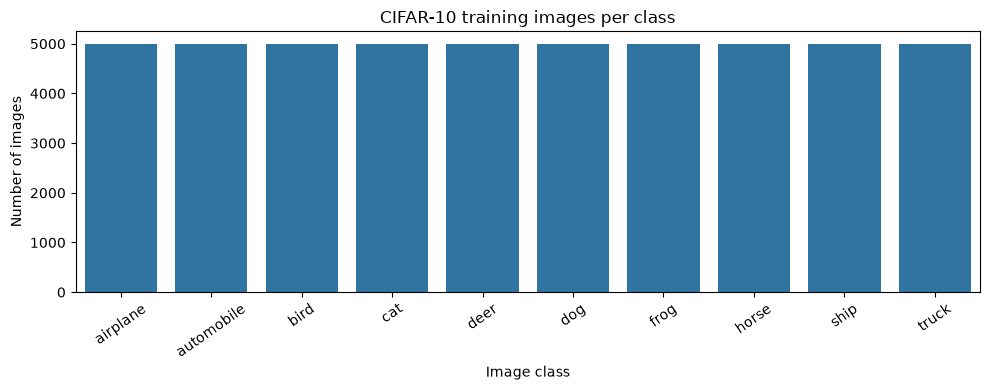

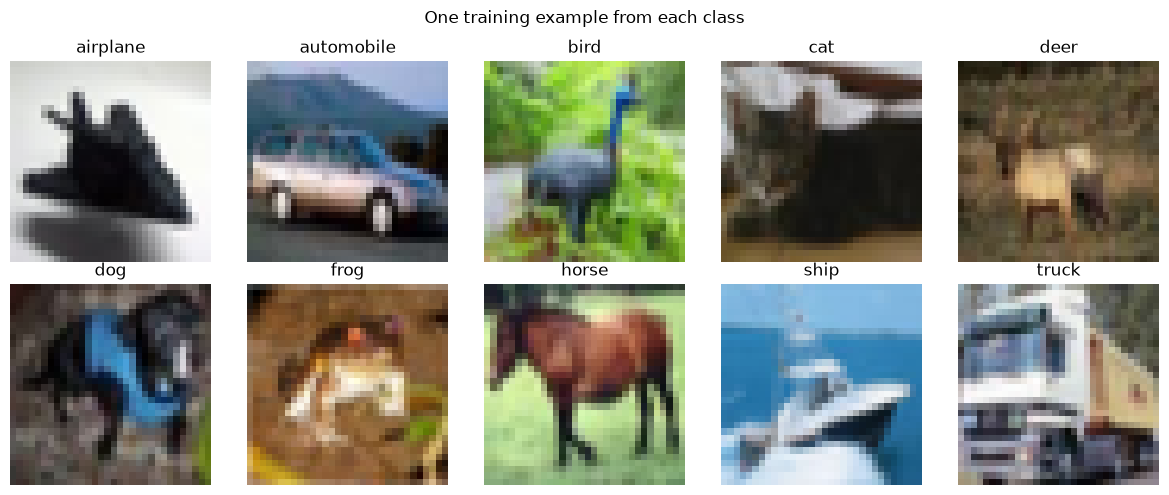

In [7]:
train_counts = pd.Series(y_train_full).value_counts().sort_index()
display(pd.DataFrame({
    "class": class_names,
    "training_records": [int(train_counts.get(i, 0)) for i in range(10)]
}))

plt.figure(figsize=(10, 4))
sns.barplot(x=class_names, y=[int(train_counts.get(i, 0)) for i in range(10)])
plt.title("CIFAR-10 training images per class")
plt.xlabel("Image class")
plt.ylabel("Number of images")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    sample_index = np.where(y_train_full == class_id)[0][0]
    ax.imshow(x_train_full[sample_index])
    ax.set_title(class_names[class_id])
    ax.axis("off")
plt.suptitle("One training example from each class")
plt.tight_layout()
plt.show()

### 5.3 Pixel and image-quality checks

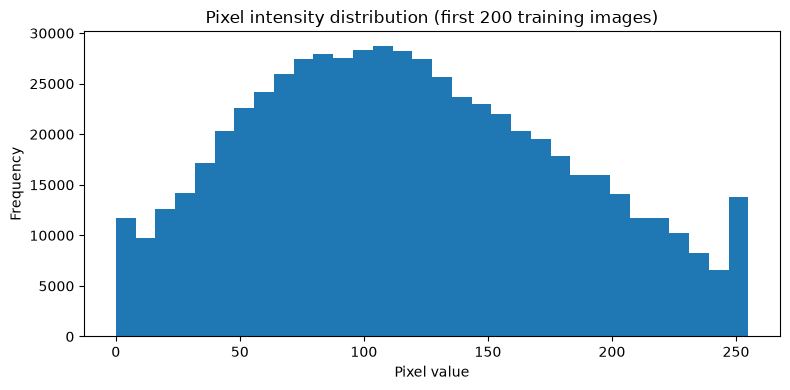

Missing values in image tensor: 0
Missing values in labels: 0
Unique training labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [8]:
# Pixel intensity distribution on a manageable sample.
pixel_sample = x_train_full[:200].ravel()
plt.figure(figsize=(8, 4))
plt.hist(pixel_sample, bins=32)
plt.title("Pixel intensity distribution (first 200 training images)")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Missing values in image tensor:", int(np.isnan(x_train_full).sum()))
print("Missing values in labels:", int(pd.isna(y_train_full).sum()))
print("Unique training labels:", sorted(np.unique(y_train_full).tolist()))

## 6. Data preparation

Pixel values are converted from integers in the range 0–255 to floating-point values in the range 0–1. A validation subset is separated from the training partition. The official test set remains untouched until final evaluation.

In [9]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Normalised pixel range:", float(x_train.min()), "to", float(x_train.max()))

Training: (40000, 32, 32, 3) (40000,)
Validation: (10000, 32, 32, 3) (10000,)
Test: (10000, 32, 32, 3) (10000,)
Normalised pixel range: 0.0 to 1.0


## 7. Baseline CNN model

A CNN is suitable because convolutional layers learn local spatial patterns from image pixels. Pooling reduces spatial dimensions, while dense layers perform final classification. The output layer has ten units, one for each CIFAR-10 class.

In [10]:
def build_baseline_model():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.30),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

baseline_model = build_baseline_model()
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Train the baseline model

Early stopping monitors validation loss and restores the best weights. The number of epochs is a maximum; training may stop earlier.

In [11]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

baseline_history = baseline_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 37ms/step - accuracy: 0.4014 - loss: 1.6151 - val_accuracy: 0.5607 - val_loss: 1.2086
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.5700 - loss: 1.2046 - val_accuracy: 0.6472 - val_loss: 1.0027
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.6399 - loss: 1.0223 - val_accuracy: 0.6834 - val_loss: 0.9146
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.6867 - loss: 0.8967 - val_accuracy: 0.6957 - val_loss: 0.8771
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.7140 - loss: 0.8133 - val_accuracy: 0.7025 - val_loss: 0.8345
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 42s 36ms/step - accuracy: 0.7413 - loss: 0.7318 - val_accuracy: 0.7145 - val_loss: 0.8161
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 35ms/step - accuracy: 0.7628 - loss: 0.6746 - val_accuracy: 0.7179 - val_loss: 0.8106
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.7808 - loss: 0.6204 - 

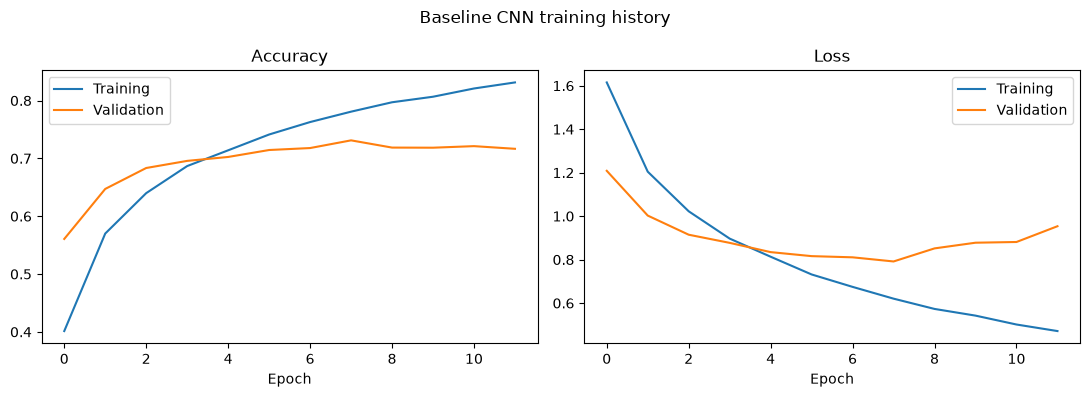

In [12]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(hist["accuracy"], label="Training")
    axes[0].plot(hist["val_accuracy"], label="Validation")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(hist["loss"], label="Training")
    axes[1].plot(hist["val_loss"], label="Validation")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(baseline_history, "Baseline CNN training history")

## 8. Baseline evaluation

Accuracy measures the proportion of correct predictions. Precision indicates how many predictions for a class were correct; recall measures how many actual examples of a class were identified; F1-score balances precision and recall. A confusion matrix shows which classes are commonly confused.

Baseline test loss: 0.8134
Baseline test accuracy: 0.7298
              precision    recall  f1-score   support

    airplane     0.7158    0.8160    0.7626      1000
  automobile     0.8415    0.8710    0.8560      1000
        bird     0.6484    0.5810    0.6129      1000
         cat     0.5432    0.5340    0.5386      1000
        deer     0.6785    0.6670    0.6727      1000
         dog     0.6589    0.5910    0.6231      1000
        frog     0.7974    0.8030    0.8002      1000
       horse     0.7547    0.8030    0.7781      1000
        ship     0.8700    0.8030    0.8352      1000
       truck     0.7733    0.8290    0.8002      1000

    accuracy                         0.7298     10000
   macro avg     0.7282    0.7298    0.7280     10000
weighted avg     0.7282    0.7298    0.7280     10000



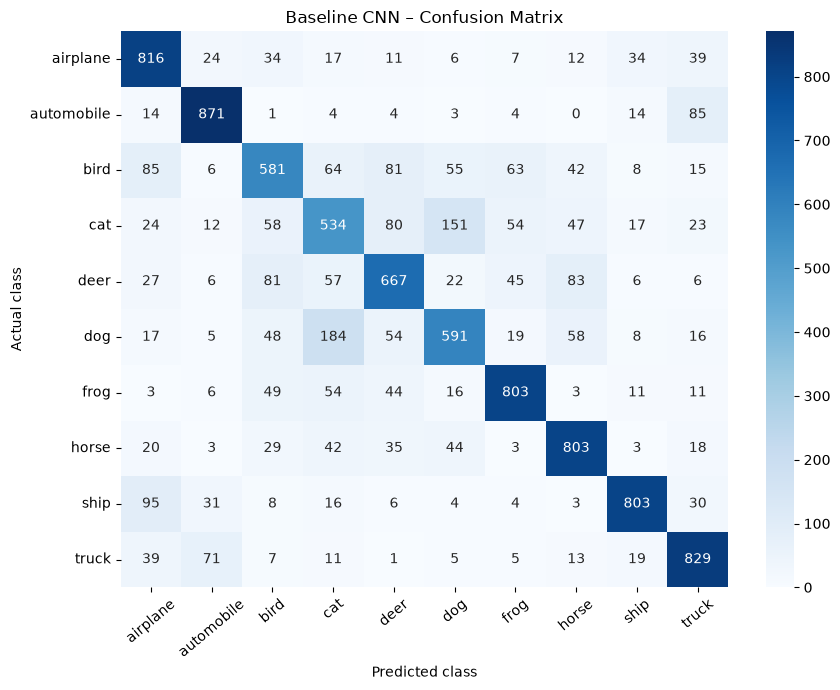

In [13]:
baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    x_test, y_test, verbose=0
)
baseline_probabilities = baseline_model.predict(x_test, verbose=0)
baseline_predictions = np.argmax(baseline_probabilities, axis=1)

print(f"Baseline test loss: {baseline_test_loss:.4f}")
print(f"Baseline test accuracy: {baseline_test_accuracy:.4f}")
print(classification_report(
    y_test, baseline_predictions,
    target_names=class_names, digits=4
))

baseline_cm = confusion_matrix(y_test, baseline_predictions)
plt.figure(figsize=(9, 7))
sns.heatmap(baseline_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Baseline CNN – Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=40)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Model improvement

The improved model adds data augmentation (random horizontal flips and translations), batch normalisation and additional dropout. Augmentation is applied only during training. It should not be assumed that the improved model is better: the test metrics must establish whether the changes helped.

In [14]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

def build_improved_model():
    inputs = keras.Input(shape=(32, 32, 3))
    x = augmentation(inputs)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0008),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

improved_model = build_improved_model()
improved_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,514 (615.29 KB)

 Trainable params: 157,322 (614.54 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 65s 98ms/step - accuracy: 0.3370 - loss: 1.7532 - val_accuracy: 0.4193 - val_loss: 1.5538 - learning_rate: 8.0000e-04
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 65s 103ms/step - accuracy: 0.4826 - loss: 1.4124 - val_accuracy: 0.5218 - val_loss: 1.3564 - learning_rate: 8.0000e-04
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 100ms/step - accuracy: 0.5436 - loss: 1.2585 - val_accuracy: 0.5861 - val_loss: 1.1285 - learning_rate: 8.0000e-04
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 100ms/step - accuracy: 0.5813 - loss: 1.1617 - val_accuracy: 0.5879 - val_loss: 1.1355 - learning_rate: 8.0000e-04
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 95ms/step - accuracy: 0.6139 - loss: 1.0904 - val_accuracy: 0.6616 - val_loss: 0.9447 - learning_rate: 8.0000e-04
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 89ms/step - accuracy: 0.6337 - loss: 1.0356 - val_accuracy: 0.6695 - val_loss: 0.9217 - learning_rate: 8.0000e-04
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 89ms/

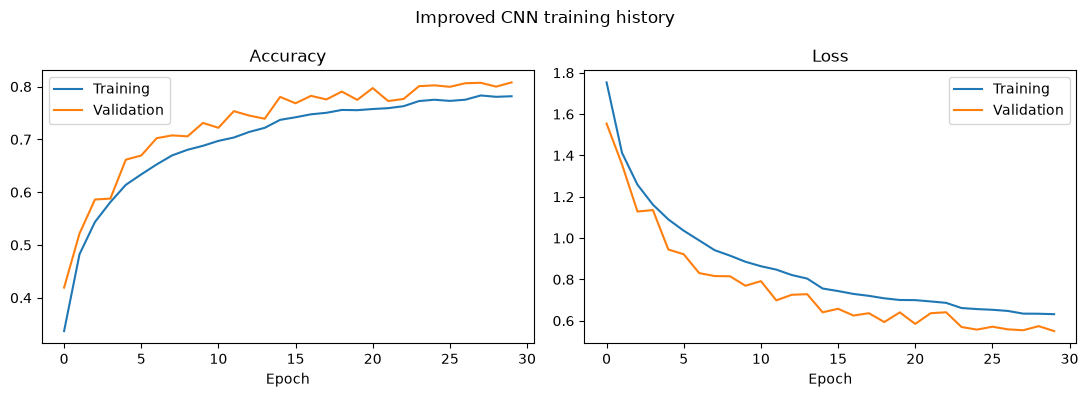

In [15]:
improved_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
)

improved_history = improved_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[improved_early_stop, reduce_lr],
    verbose=1
)
plot_history(improved_history, "Improved CNN training history")

## 10. Final evaluation and comparison

Both models are evaluated against the same held-out test set. Select the model based on the evidence, not on the assumption that a more complex model must perform better.

,Model,Test loss,Test accuracy
0,Baseline CNN,0.813410,0.7298
1,Improved CNN,0.569979,0.8079


Improved model classification report:
              precision    recall  f1-score   support

    airplane     0.7863    0.8720    0.8269      1000
  automobile     0.8822    0.9440    0.9121      1000
        bird     0.8091    0.6610    0.7276      1000
         cat     0.7250    0.6010    0.6572      1000
        deer     0.8283    0.7190    0.7698      1000
         dog     0.7978    0.7180    0.7558      1000
        frog     0.6467    0.9370    0.7652      1000
       horse     0.8619    0.8550    0.8584      1000
        ship     0.9393    0.8670    0.9017      1000
       truck     0.8677    0.9050    0.8860      1000

    accuracy                         0.8079     10000
   macro avg     0.8144    0.8079    0.8061     10000
weighted avg     0.8144    0.8079    0.8061     10000



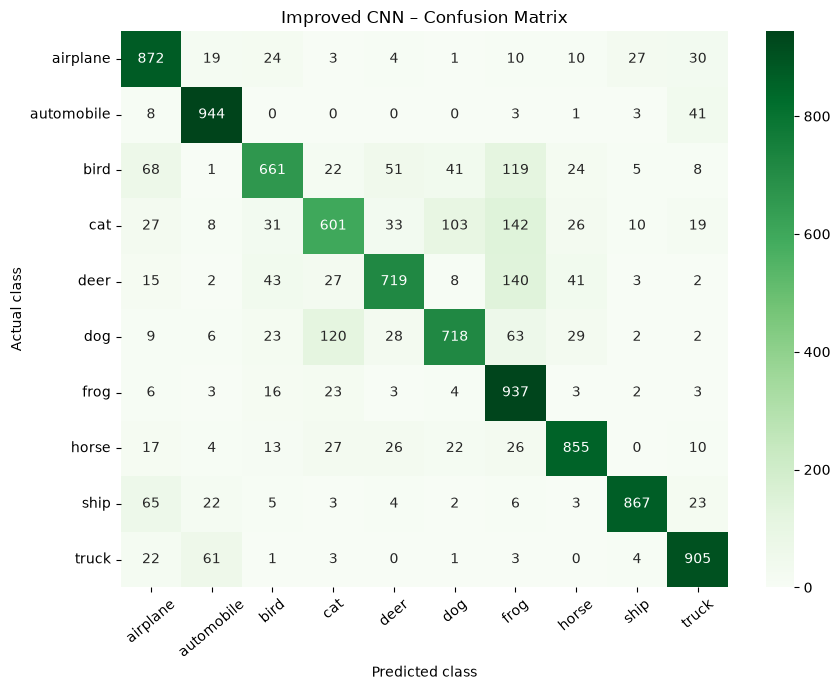

In [16]:
improved_test_loss, improved_test_accuracy = improved_model.evaluate(
    x_test, y_test, verbose=0
)
improved_probabilities = improved_model.predict(x_test, verbose=0)
improved_predictions = np.argmax(improved_probabilities, axis=1)

comparison = pd.DataFrame([
    {"Model": "Baseline CNN", "Test loss": baseline_test_loss,
     "Test accuracy": baseline_test_accuracy},
    {"Model": "Improved CNN", "Test loss": improved_test_loss,
     "Test accuracy": improved_test_accuracy}
])
display(comparison)

print("Improved model classification report:")
print(classification_report(
    y_test, improved_predictions,
    target_names=class_names, digits=4
))

improved_cm = confusion_matrix(y_test, improved_predictions)
plt.figure(figsize=(9, 7))
sns.heatmap(improved_cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Improved CNN – Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=40)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 10.1 Inspect individual predictions

This helps identify examples the model classifies correctly and incorrectly. Do not use a few examples as a substitute for quantitative evaluation.

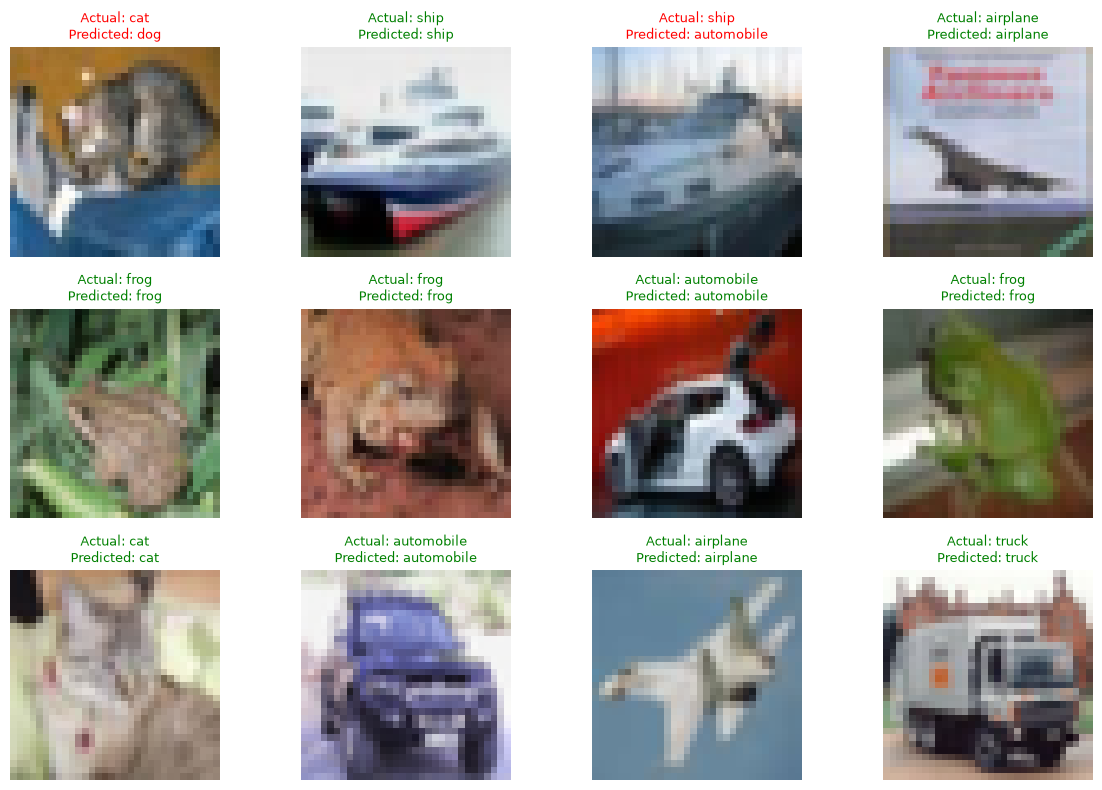

In [17]:
n = 12
plt.figure(figsize=(12, 8))
for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i])
    predicted = class_names[int(improved_predictions[i])]
    actual = class_names[int(y_test[i])]
    plt.title(f"Actual: {actual}\nPredicted: {predicted}",
              color=("green" if predicted == actual else "red"), fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Interpretation, limitations and recommendations

Use the actual metrics and plots generated above to discuss:
- Whether the model generalises: compare training, validation and test performance.
- Which classes have the strongest and weakest precision, recall and F1-score.
- Which class pairs are confused most often and plausible visual reasons.
- Whether augmentation and regularisation improved test performance.
- Whether the difference is meaningful for the publisher's proof-of-concept objective.

**Limitations:** CIFAR-10 images are small and curated. The ten categories do not include people, faces, identities, access-control events or CCTV conditions. Results cannot be transferred directly to a real premises security system. A future facial-recognition project would require an appropriately governed face dataset, consent and privacy assessment, representative testing, bias and error analysis, security controls and human oversight.

**Recommendation:** Treat this model as an educational image-classification prototype only. Before any operational deployment, conduct a separate requirements, privacy, security, fairness and real-world validation study.

## 12. Save model artefacts and close Spark

The notebook saves both trained models and a CSV comparison table. Include these artefacts in the submission if requested by your lecturer/campus.

In [18]:
os.makedirs("outputs", exist_ok=True)
baseline_model.save("outputs/cifar10_baseline_cnn.keras")
improved_model.save("outputs/cifar10_improved_cnn.keras")
comparison.to_csv("outputs/model_comparison.csv", index=False)
print("Saved models and comparison table in ./outputs/")

Saved models and comparison table in ./outputs/


In [19]:
spark.stop()

## 13. References

- Krizhevsky, A. (2009) *Learning multiple layers of features from tiny images*. University of Toronto. Available at: https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf (Accessed: insert your access date).
- TensorFlow (n.d.) *CIFAR-10 small images classification dataset*. Available at: https://www.tensorflow.org/api_docs/python/tf/keras/datasets/cifar10 (Accessed: insert your access date).
- TensorFlow (n.d.) *Convolutional layers*. Available at: https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D (Accessed: insert your access date).
- TensorFlow (n.d.) *Image data augmentation*. Available at: https://www.tensorflow.org/tutorials/images/data_augmentation (Accessed: insert your access date).
- PySpark (n.d.) *Spark SQL and DataFrames*. Available at: https://spark.apache.org/docs/latest/sql-programming-guide.html (Accessed: insert your access date).